# SP-5 — Clusterização de bairros e escolha de k

**Squad Inteligência · spike de 1 dia · Sprint 1**

**Pergunta:** os 94 bairros se organizam em quantos perfis territoriais? Qual k é defensável com as variáveis que temos hoje?

**Aceite:** notebook com silhouette + dendrograma + resumo de 1 página para o orientador.

**Método:** variáveis territoriais padronizadas → Ward (hierárquico) → silhouette para k=2..8 → estabilidade por bootstrap (ARI) → Kruskal-Wallis da incidência entre clusters. O desfecho (casos) fica **fora** da clusterização para não criar circularidade.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

for candidato in (Path.cwd(), Path.cwd() / "backend" / "notebooks"):
    if (candidato / "_comum.py").exists():
        sys.path.insert(0, str(candidato))
        break
else:
    raise RuntimeError("Rode o notebook em backend/notebooks ou na raiz do repo")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _comum

_comum.SAIDAS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
np.random.seed(42)
print("saídas em", _comum.SAIDAS_DIR)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import kruskal
from matplotlib.patches import Patch


saídas em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas


## 1. Variáveis disponíveis

O painel só tem, por enquanto, proxies territoriais estáticos: vulnerabilidade (ZEIS), área de ZEIS e área do bairro. **IDH (US09), densidade (US08), intermitência (US13) e LST (US11) ainda não chegaram** — o resultado é preliminar e deve ser reexecutado na S2.

Casos entram apenas como **validação externa** (Kruskal-Wallis), nunca como feature.


In [2]:
painel = _comum.carregar_painel(anos=[2024, 2025])

casos_2024 = (
    painel[painel.semana.floordiv(100) == 2024]
    .groupby("bairro_norm", as_index=False)["casos"].sum()
    .rename(columns={"casos": "casos_2024"})
)
casos_2025 = (
    painel[painel.semana.floordiv(100) == 2025]
    .groupby("bairro_norm", as_index=False)["casos"].sum()
    .rename(columns={"casos": "casos_2025"})
)
for d in (casos_2024, casos_2025):
    d["key"] = d["bairro_norm"]

geo = _comum.carregar_geo()[["key", "EBAIRRNOME", "CDISTSANTPSAD", "area_km2", "geometry"]]
lookup = _comum.carregar_lookup()[["key", "vulnerabilidade_score", "historico_score", "zeis_ha"]]

tab = (
    geo.merge(casos_2024[["key", "casos_2024"]], on="key")
    .merge(casos_2025[["key", "casos_2025"]], on="key")
    .merge(lookup, on="key")
)
tab["casos_medios"] = (tab["casos_2024"] + tab["casos_2025"]) / 2
tab["casos_por_km2"] = tab["casos_medios"] / tab["area_km2"]
tab["log_zeis"] = np.log1p(tab["zeis_ha"])
tab["log_area"] = np.log1p(tab["area_km2"])
tab["log_casos"] = np.log1p(tab["casos_medios"])
tab["historico_alto"] = (tab["historico_score"] >= 75).astype(int)

vars_primarias = ["vulnerabilidade_score", "log_zeis", "log_area"]

print("bairros:", len(tab))
display(tab[vars_primarias + ["casos_medios", "casos_por_km2", "historico_alto"]].describe().round(2))
print("\nCorrelação de Spearman com casos médios (só leitura, não entra no modelo):")
display(tab[vars_primarias + ["casos_medios"]].corr(method="spearman").round(2))

bairros: 94


,vulnerabilidade_score,log_zeis,log_area,casos_medios,casos_por_km2,historico_alto
count,94.00,94.00,94.00,94.00,94.00,94.00
mean,50.75,1.22,0.86,97.14,69.82,0.11
std,30.11,1.65,0.66,108.94,54.06,0.31
min,25.00,0.00,0.13,0.00,0.00,0.00
25%,25.00,0.00,0.40,25.62,30.59,0.00
50%,25.00,0.00,0.62,53.00,59.80,0.00
75%,84.40,2.61,1.09,126.75,89.47,0.00
max,100.00,5.85,3.85,501.00,297.93,1.00



Correlação de Spearman com casos médios (só leitura, não entra no modelo):


,vulnerabilidade_score,log_zeis,log_area,casos_medios
vulnerabilidade_score,1.00,0.96,0.47,0.53
log_zeis,0.96,1.00,0.47,0.51
log_area,0.47,0.47,1.00,0.69
casos_medios,0.53,0.51,0.69,1.00


## 2. Escolha de k: silhouette + estabilidade

Para cada k de 2 a 8, calculamos o silhouette médio e o tamanho do menor cluster. Para k de 2 a 5, medimos a estabilidade por bootstrap (30 reamostragens, ARI contra a solução completa).

Critérios de admissibilidade: **menor cluster ≥ 10** e **ARI mínimo ≥ 0,4**. Entre os admissíveis, escolhemos o maior silhouette.


In [3]:
X = StandardScaler().fit_transform(tab[vars_primarias])


def estabilidade(X, k, n_boot=30):
    base = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    aris = []
    for b in range(n_boot):
        rng = np.random.default_rng(42 + b)
        idx = rng.choice(len(X), len(X), replace=True)
        if len(np.unique(idx)) < k:
            continue
        alt = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X[idx])
        aris.append(adjusted_rand_score(base[idx], alt))
    return float(np.mean(aris)), float(np.min(aris))


linhas = []
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    sil = silhouette_score(X, lab)
    tamanhos = np.bincount(lab)
    ari_medio = ari_min = np.nan
    if k <= 5:
        ari_medio, ari_min = estabilidade(X, k)
    linhas.append({
        "k": k, "silhouette": sil, "menor_cluster": int(tamanhos.min()),
        "tamanhos": tamanhos.tolist(), "ARI_medio": ari_medio, "ARI_minimo": ari_min,
    })

tabela_k = pd.DataFrame(linhas)
tabela_k[["silhouette", "ARI_medio", "ARI_minimo"]] = tabela_k[["silhouette", "ARI_medio", "ARI_minimo"]].round(3)
display(tabela_k)
tabela_k.to_csv(_comum.SAIDAS_DIR / "sp5_escolha_k.csv", index=False)

admissiveis = tabela_k[(tabela_k["menor_cluster"] >= 10) & (tabela_k["ARI_minimo"] >= 0.4)]
K_ESCOLHIDO = int(admissiveis.sort_values("silhouette", ascending=False).iloc[0]["k"])
print("k admissíveis:", admissiveis["k"].tolist())
print("k escolhido:", K_ESCOLHIDO)

,k,silhouette,menor_cluster,tamanhos,ARI_medio,ARI_minimo
0,2,0.571,26,"[68, 26]",0.667,0.174
1,3,0.468,19,"[26, 49, 19]",0.768,0.496
2,4,0.505,6,"[49, 6, 19, 20]",0.838,0.523
3,5,0.528,6,"[6, 20, 19, 12, 37]",0.820,0.624
4,6,0.523,1,"[19, 20, 5, 12, 37, 1]",NaN,NaN
5,7,0.541,1,"[20, 14, 5, 12, 37, 1, 5]",NaN,NaN
6,8,0.537,1,"[10, 14, 5, 12, 37, 1, 5, 10]",NaN,NaN


k admissíveis: [3]
k escolhido: 3


figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp5_silhouette_por_k.png


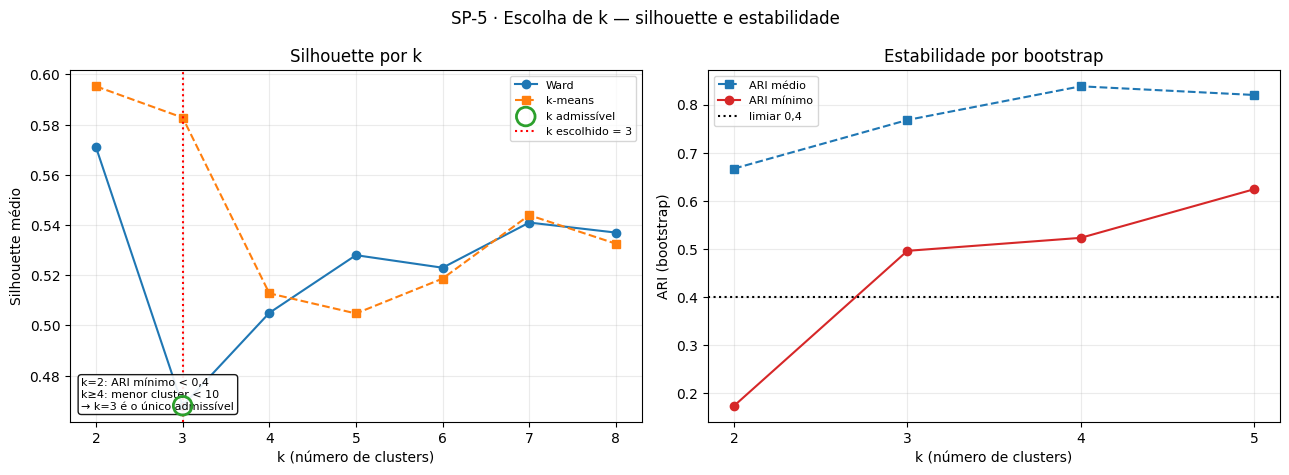

In [4]:
resultados_kmeans = []
for k in range(2, 9):
    lab_k = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)
    resultados_kmeans.append({"k": k, "silhouette_kmeans": silhouette_score(X, lab_k)})
kmeans_df = pd.DataFrame(resultados_kmeans)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.plot(tabela_k["k"], tabela_k["silhouette"], marker="o", label="Ward")
ax.plot(kmeans_df["k"], kmeans_df["silhouette_kmeans"], marker="s", linestyle="--", label="k-means")
ax.scatter(admissiveis["k"], admissiveis["silhouette"], s=180, facecolors="none",
           edgecolors="#2ca02c", linewidths=2, label="k admissível", zorder=5)
ax.axvline(K_ESCOLHIDO, color="red", linestyle=":", label=f"k escolhido = {K_ESCOLHIDO}")
ax.set_xlabel("k (número de clusters)")
ax.set_ylabel("Silhouette médio")
ax.set_title("Silhouette por k")
ax.set_xticks(range(2, 9))
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="upper right")
ax.text(0.02, 0.03, "k=2: ARI mínimo < 0,4\nk≥4: menor cluster < 10\n→ k=3 é o único admissível",
        transform=ax.transAxes, fontsize=8, va="bottom",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.9))

ax = axes[1]
ari = tabela_k.dropna(subset=["ARI_minimo"])
ax.plot(ari["k"], ari["ARI_medio"], marker="s", linestyle="--", label="ARI médio")
ax.plot(ari["k"], ari["ARI_minimo"], marker="o", color="#d62728", label="ARI mínimo")
ax.axhline(0.4, color="black", linestyle=":", label="limiar 0,4")
ax.set_xlabel("k (número de clusters)")
ax.set_ylabel("ARI (bootstrap)")
ax.set_title("Estabilidade por bootstrap")
ax.set_xticks(range(2, 6))
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle("SP-5 · Escolha de k — silhouette e estabilidade")
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp5_silhouette_por_k.png")
print("figura salva em", caminho)
plt.show()

## 3. Dendrograma (Ward)

figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp5_dendrograma.png


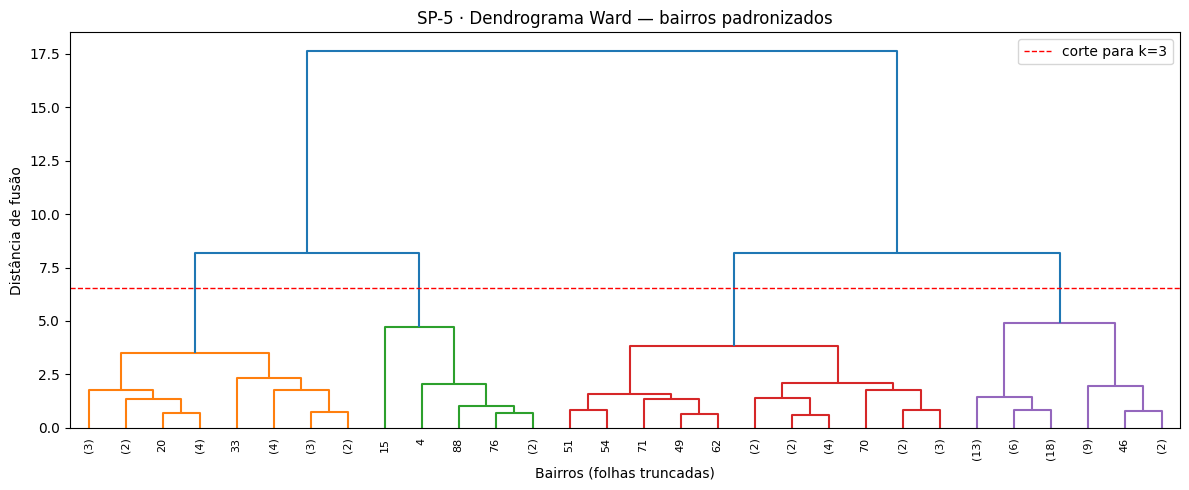

In [5]:
Z = linkage(X, method="ward")
corte = (Z[-(K_ESCOLHIDO + 1), 2] + Z[-K_ESCOLHIDO, 2]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
           color_threshold=corte, ax=ax)
ax.axhline(corte, color="red", linestyle="--", linewidth=1, label=f"corte para k={K_ESCOLHIDO}")
ax.set_title("SP-5 · Dendrograma Ward — bairros padronizados")
ax.set_xlabel("Bairros (folhas truncadas)")
ax.set_ylabel("Distância de fusão")
ax.legend()
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp5_dendrograma.png")
print("figura salva em", caminho)
plt.show()

## 4. Clusters escolhidos e perfis

In [6]:
lab = AgglomerativeClustering(n_clusters=K_ESCOLHIDO, linkage="ward").fit_predict(X)
tab["cluster"] = lab

perfis = tab.groupby("cluster").agg(
    n=("key", "size"),
    casos_medios=("casos_medios", "mean"),
    casos_por_km2=("casos_por_km2", "mean"),
    vulnerabilidade=("vulnerabilidade_score", "mean"),
    zeis_ha=("zeis_ha", "mean"),
    area_km2=("area_km2", "mean"),
).round(2)
perfis["share_ZEIS"] = tab.groupby("cluster")["zeis_ha"].apply(lambda s: (s > 0).mean()).round(2)
display(perfis)
perfis.to_csv(_comum.SAIDAS_DIR / "sp5_perfis_clusters.csv")

kw = kruskal(*[tab.loc[tab["cluster"] == c, "casos_medios"] for c in range(K_ESCOLHIDO)])
print(f"Kruskal-Wallis (casos médios entre clusters): H={kw.statistic:.2f} | p={kw.pvalue:.2e}")

,n,casos_medios,casos_por_km2,vulnerabilidade,zeis_ha,area_km2,share_ZEIS
cluster,,,,,,,
0,26,172.42,67.75,90.03,54.66,5.36,0.96
1,49,50.76,70.34,25.00,0.00,0.92,0.00
2,19,113.76,71.32,63.42,2.96,1.87,0.89


Kruskal-Wallis (casos médios entre clusters): H=24.66 | p=4.41e-06


figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp5_silhouette_clusters.png


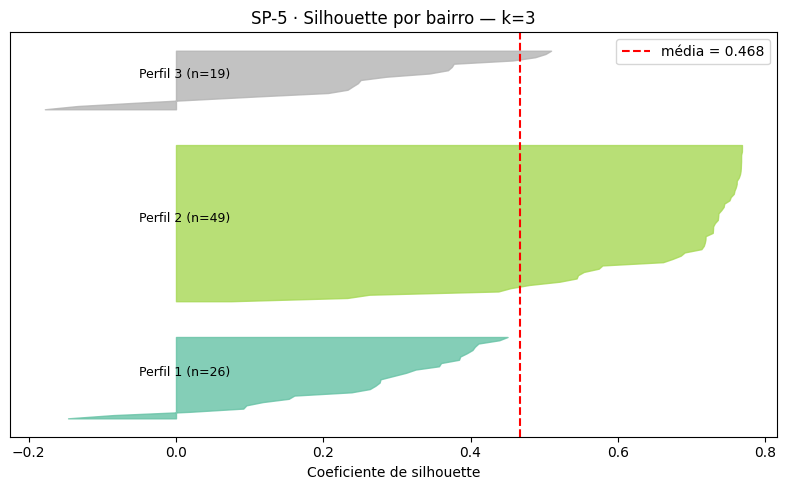

In [7]:
sil_vals = silhouette_samples(X, lab)
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
cores = plt.cm.Set2(np.linspace(0, 1, K_ESCOLHIDO))
for c in range(K_ESCOLHIDO):
    vals = np.sort(sil_vals[lab == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=cores[c], alpha=0.8)
    ax.text(-0.05, y_lower + 0.5 * len(vals), f"Perfil {c + 1} (n={len(vals)})", fontsize=9)
    y_lower = y_upper + 10

media = silhouette_score(X, lab)
ax.axvline(media, color="red", linestyle="--", label=f"média = {media:.3f}")
ax.set_xlabel("Coeficiente de silhouette")
ax.set_yticks([])
ax.set_title(f"SP-5 · Silhouette por bairro — k={K_ESCOLHIDO}")
ax.legend()
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp5_silhouette_clusters.png")
print("figura salva em", caminho)
plt.show()

## 5. Mapa dos perfis

figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp5_mapa_clusters.png


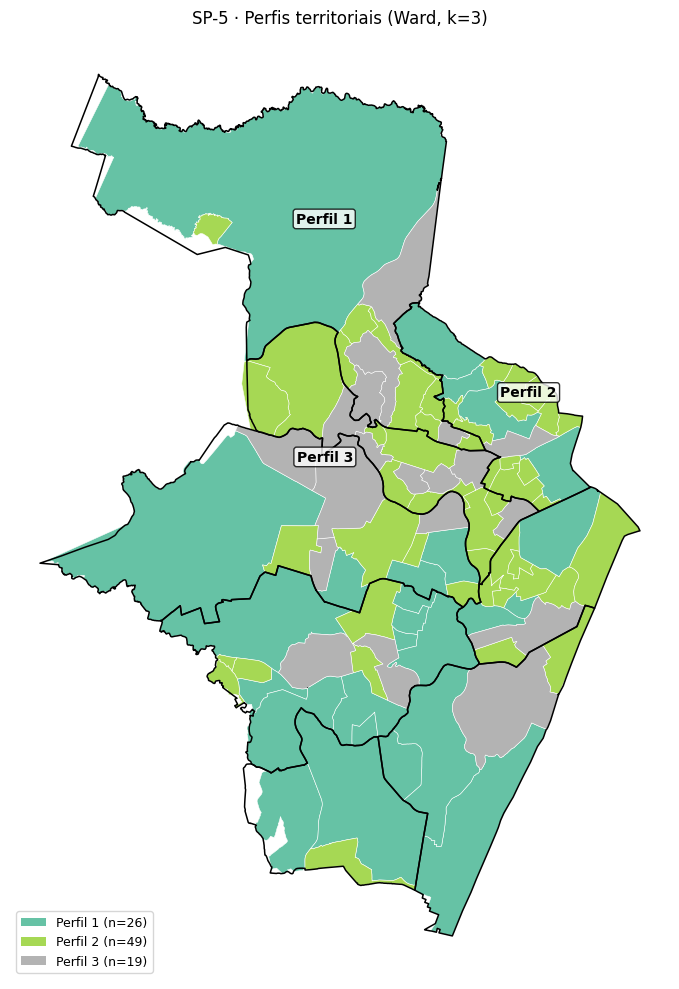

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))
for c in range(K_ESCOLHIDO):
    m = tab["cluster"] == c
    tab[m].plot(ax=ax, color=cores[c], edgecolor="white", linewidth=0.4)

distritos = _comum.carregar_distritos().to_crs(tab.crs)
distritos.boundary.plot(ax=ax, color="black", linewidth=1.1)

for c in range(K_ESCOLHIDO):
    sub = tab[tab["cluster"] == c]
    p = sub.geometry.union_all().representative_point() if hasattr(sub.geometry, "union_all") else sub.geometry.unary_union.representative_point()
    ax.annotate(f"Perfil {c + 1}", (p.x, p.y), fontsize=10, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))

ax.set_title(f"SP-5 · Perfis territoriais (Ward, k={K_ESCOLHIDO})")
ax.axis("off")
legenda = [Patch(facecolor=cores[c], label=f"Perfil {c + 1} (n={int((tab['cluster'] == c).sum())})") for c in range(K_ESCOLHIDO)]
ax.legend(handles=legenda, loc="lower left", fontsize=9, frameon=True)
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp5_mapa_clusters.png")
print("figura salva em", caminho)
plt.show()

## 6. Sensibilidade: o que muda ao incluir o desfecho

Se colocarmos casos (ou o histórico de surto) dentro da clusterização, os perfis passam a descrever o próprio desfecho — circularidade. A tabela abaixo mostra por que o modelo primário fica só com variáveis territoriais.


In [9]:
sens = []
for nome, cols in [
    ("territorial (primário)", vars_primarias),
    ("+ histórico de surto", vars_primarias + ["historico_alto"]),
    ("+ casos médios (circular)", vars_primarias + ["log_casos"]),
]:
    Xa = StandardScaler().fit_transform(tab[cols])
    la = AgglomerativeClustering(n_clusters=K_ESCOLHIDO, linkage="ward").fit_predict(Xa)
    sens.append({"especificacao": nome, "silhouette": silhouette_score(Xa, la),
                 "tamanhos": np.bincount(la).tolist()})
display(pd.DataFrame(sens).round(3))

,especificacao,silhouette,tamanhos
0,territorial (primário),0.468,"[26, 49, 19]"
1,+ histórico de surto,0.584,"[25, 59, 10]"
2,+ casos médios (circular),0.313,"[27, 54, 13]"


## 7. Leitura e limitações

- A estrutura defensável com os dados atuais tem **3 perfis**; o número não é uma verdade do território, é o que os proxies disponíveis sustentam.
- O silhouette é moderado (≈0,47): os grupos se sobrepõem. Isso é esperado com poucas variáveis e escalas discretas (vulnerabilidade e ZEIS).
- `log_area` e `log_zeis` são proxies grosseiros; **densidade, IDH, intermitência e LST** devem mudar os perfis na S2.
- A validação externa (Kruskal-Wallis) mostra que os clusters se diferenciam em casos, mas parte disso é tamanho populacional, não risco.
- Sem população, não há como separar "bairro populoso" de "bairro de alto risco". Reexecutar com US08 antes de US21.


In [10]:
print("=== Resumo SP-5 ===")
print("Variáveis:", vars_primarias)
print("k escolhido:", K_ESCOLHIDO, "| silhouette:", round(silhouette_score(X, lab), 3))
print("Tamanhos:", np.bincount(lab).tolist())
print("Kruskal-Wallis p:", f"{kw.pvalue:.2e}")
print("\nPerfis (médias em unidade original):")
display(perfis)

saida = tab[["key", "EBAIRRNOME", "CDISTSANTPSAD", "cluster", "casos_2024", "casos_2025",
             "casos_medios", "casos_por_km2", "vulnerabilidade_score", "zeis_ha", "area_km2"]].copy()
saida["EBAIRRNOME"] = saida["EBAIRRNOME"].str.title()
saida.sort_values(["cluster", "casos_medios"], ascending=[True, False]).to_csv(
    _comum.SAIDAS_DIR / "sp5_bairros_clusters.csv", index=False)
print("tabela por bairro:", _comum.SAIDAS_DIR / "sp5_bairros_clusters.csv")

=== Resumo SP-5 ===
Variáveis: ['vulnerabilidade_score', 'log_zeis', 'log_area']
k escolhido: 3 | silhouette: 0.468
Tamanhos: [26, 49, 19]
Kruskal-Wallis p: 4.41e-06

Perfis (médias em unidade original):


,n,casos_medios,casos_por_km2,vulnerabilidade,zeis_ha,area_km2,share_ZEIS
cluster,,,,,,,
0,26,172.42,67.75,90.03,54.66,5.36,0.96
1,49,50.76,70.34,25.00,0.00,0.92,0.00
2,19,113.76,71.32,63.42,2.96,1.87,0.89


tabela por bairro: /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp5_bairros_clusters.csv
